<a href="https://colab.research.google.com/github/katiyardivyanshu08-bit/Retail_Pulse_Project_/blob/main/2_Retail_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [68]:
import pandas as pd
# Statistical visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
# Ignore warnings
import warnings
warnings.filterwarnings('ignore')
# Getting access
# from google.colab import drive
# drive.mount('/content/drive')

In [69]:
# df=pd.read_csv("/content/drive/MyDrive/Retail_Pulse_Project/1_Data/After_clean_retailpulse.csv")
url = "https://raw.githubusercontent.com/katiyardivyanshu08-bit/Retail_Pulse_Project_/main/Data/Main_Clean.csv"
df = pd.read_csv(url)
df.head()


,CustomerID,Age,Gender,Region,ProductCategory,AnnualIncome,PurchaseFrequency,AnnualPurchaseAmount,LastPurchaseDate,CustomerTenure,DiscountUsage,ReturnRate,CustomerSegment
0,204242,50,male,north,beauty,57328.90,4.0,10206.51,2025-09-07,3.16,0.3790,0.0929,regular
1,299677,36,male,east,clothing,66674.05,1.0,5497.05,2025-11-05,7.11,0.2153,0.0251,regular
2,240200,37,male,central,electronics,39673.95,2.0,5850.72,2025-10-20,6.43,0.1474,0.1273,budget
3,232815,36,male,south,clothing,70271.46,11.0,10174.37,2025-12-01,2.50,0.1379,0.0133,regular
4,508698,30,female,west,home & kitchen,67653.56,6.0,10441.58,2025-12-30,3.21,0.0958,0.0853,regular


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 499000 entries, 0 to 498999
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   CustomerID            499000 non-null  int64  
 1   Age                   499000 non-null  int64  
 2   Gender                496006 non-null  object 
 3   Region                495507 non-null  object 
 4   ProductCategory       496006 non-null  object 
 5   AnnualIncome          494010 non-null  float64
 6   PurchaseFrequency     495008 non-null  float64
 7   AnnualPurchaseAmount  499000 non-null  float64
 8   LastPurchaseDate      499000 non-null  object 
 9   CustomerTenure        499000 non-null  float64
 10  DiscountUsage         494010 non-null  float64
 11  ReturnRate            495507 non-null  float64
 12  CustomerSegment       499000 non-null  object 
dtypes: float64(6), int64(2), object(5)
memory usage: 49.5+ MB


In [71]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

CustomerID                 0
Age                        0
Gender                  2994
Region                  3493
ProductCategory         2994
AnnualIncome            4990
PurchaseFrequency       3992
AnnualPurchaseAmount       0
LastPurchaseDate           0
CustomerTenure             0
DiscountUsage           4990
ReturnRate              3493
CustomerSegment            0
dtype: int64
Duplicate rows: 0


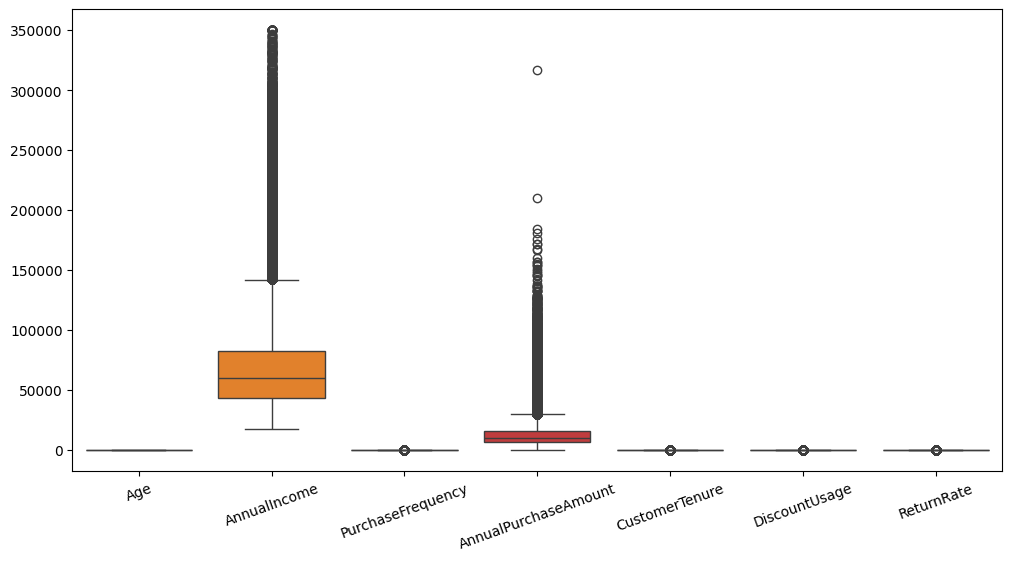

In [72]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[["Age", "AnnualIncome", "PurchaseFrequency",
    "AnnualPurchaseAmount", "CustomerTenure",
    "DiscountUsage", "ReturnRate"]])
plt.xticks(rotation=20)
plt.show()

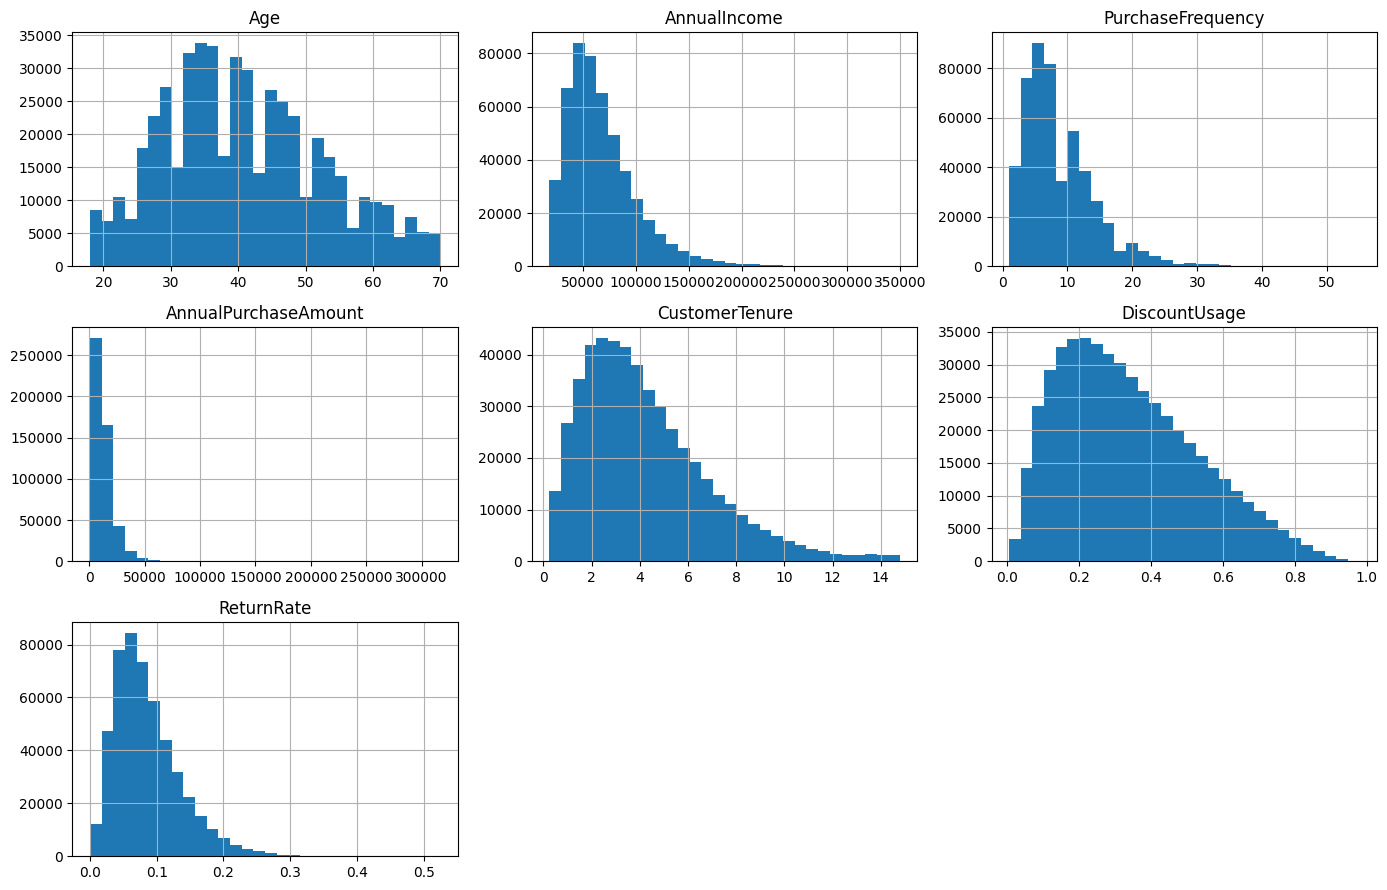

In [73]:
num_cols = [
    "Age", "AnnualIncome", "PurchaseFrequency",
    "AnnualPurchaseAmount", "CustomerTenure",
    "DiscountUsage", "ReturnRate"
]

df[num_cols].hist(figsize=(14, 9), bins=30)
plt.tight_layout()
plt.show()

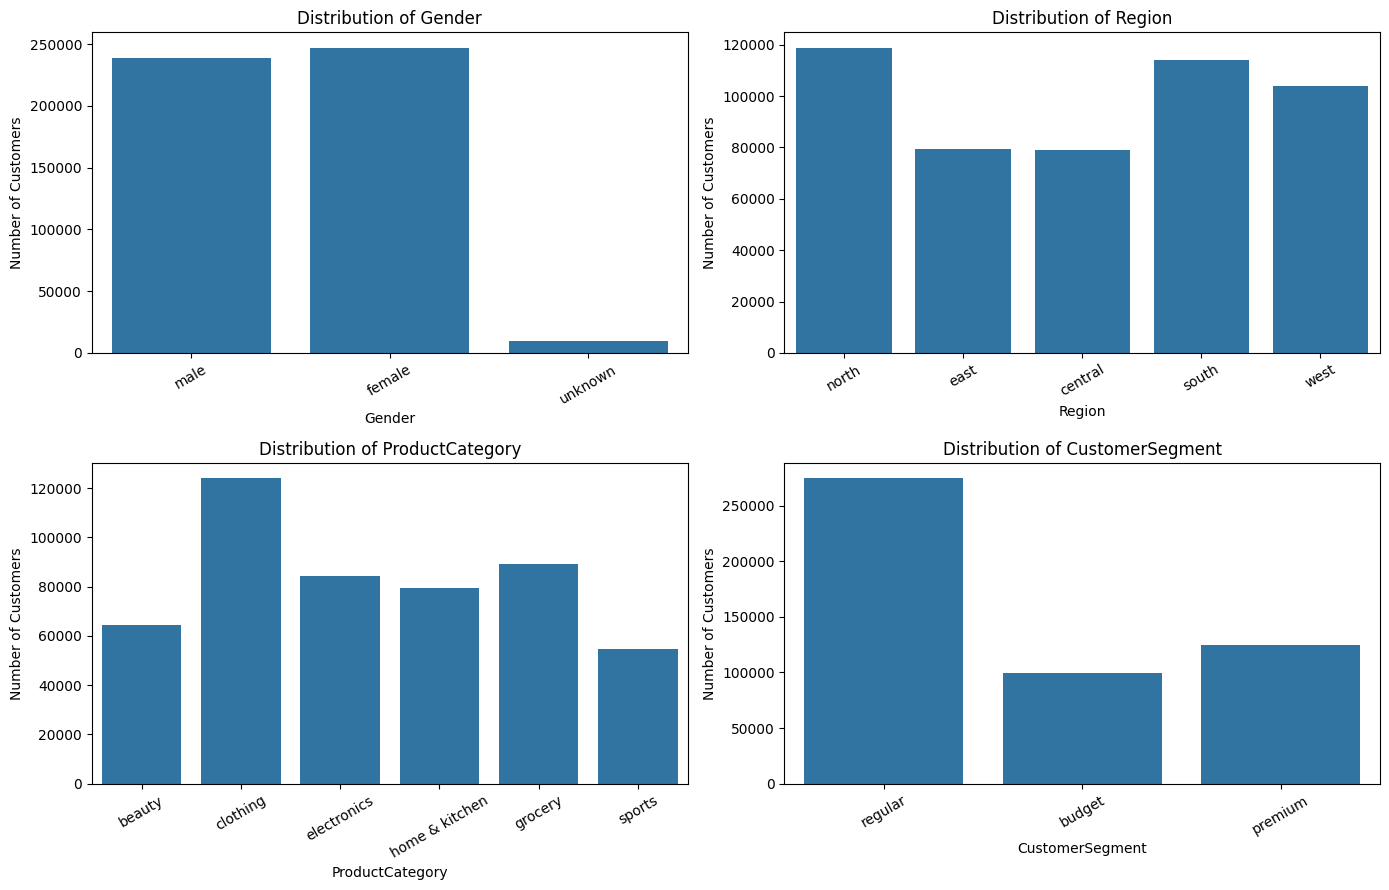

In [74]:
cat_cols = ["Gender", "Region", "ProductCategory", "CustomerSegment"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Number of Customers")
    axes[i].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

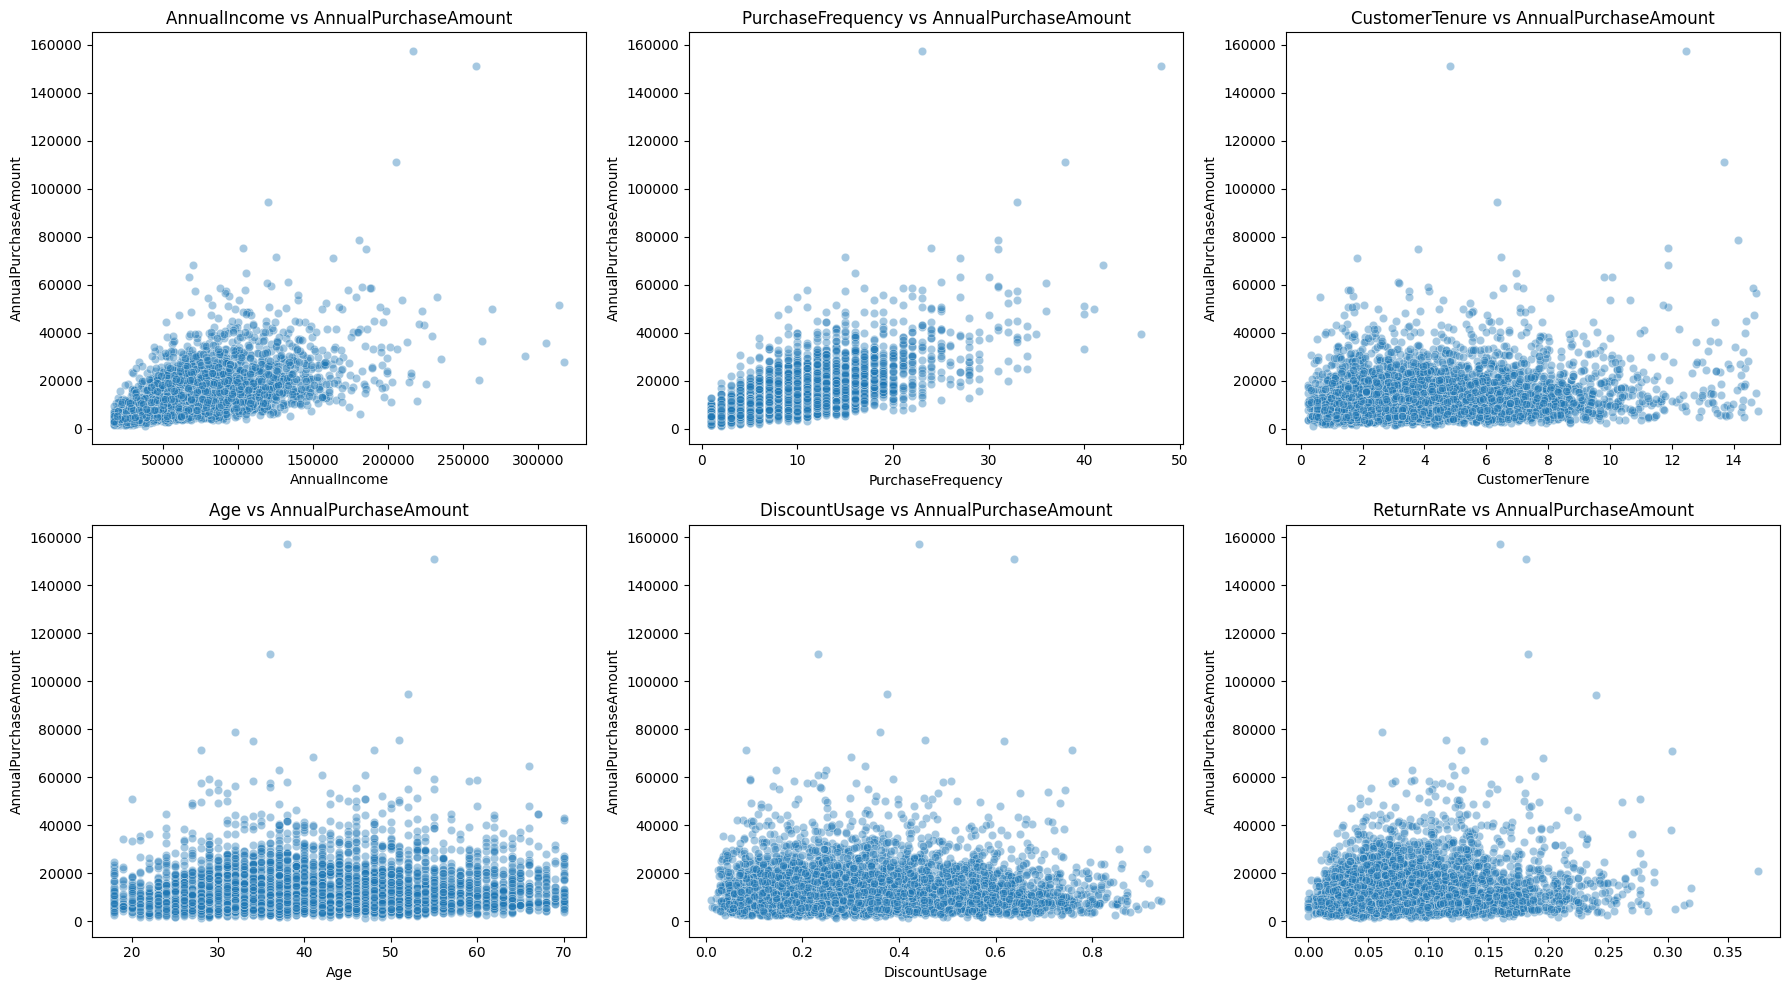

In [75]:
features = [
    "AnnualIncome",
    "PurchaseFrequency",
    "CustomerTenure",
    "Age",
    "DiscountUsage",
    "ReturnRate"
]

data = df.sample(min(5000, len(df)), random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.scatterplot(
        data=data,
        x=col,
        y="AnnualPurchaseAmount",
        alpha=0.4,
        ax=axes[i]
    )
    axes[i].set_title(f"{col} vs AnnualPurchaseAmount")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("AnnualPurchaseAmount")

plt.tight_layout()
plt.show()

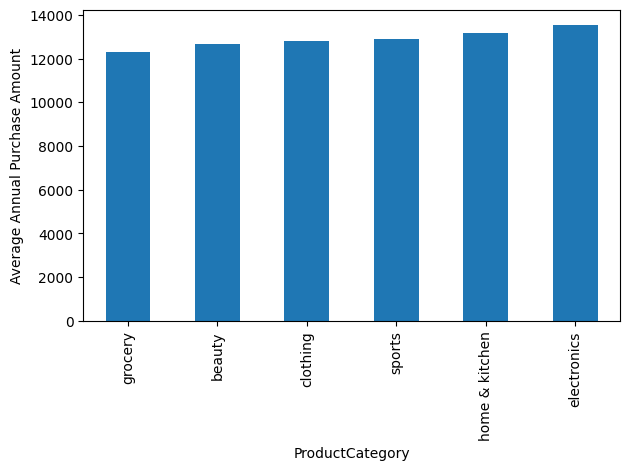

In [76]:
df.groupby("ProductCategory")["AnnualPurchaseAmount"].mean().sort_values().plot(kind="bar")
plt.ylabel("Average Annual Purchase Amount")
plt.tight_layout()
plt.show()

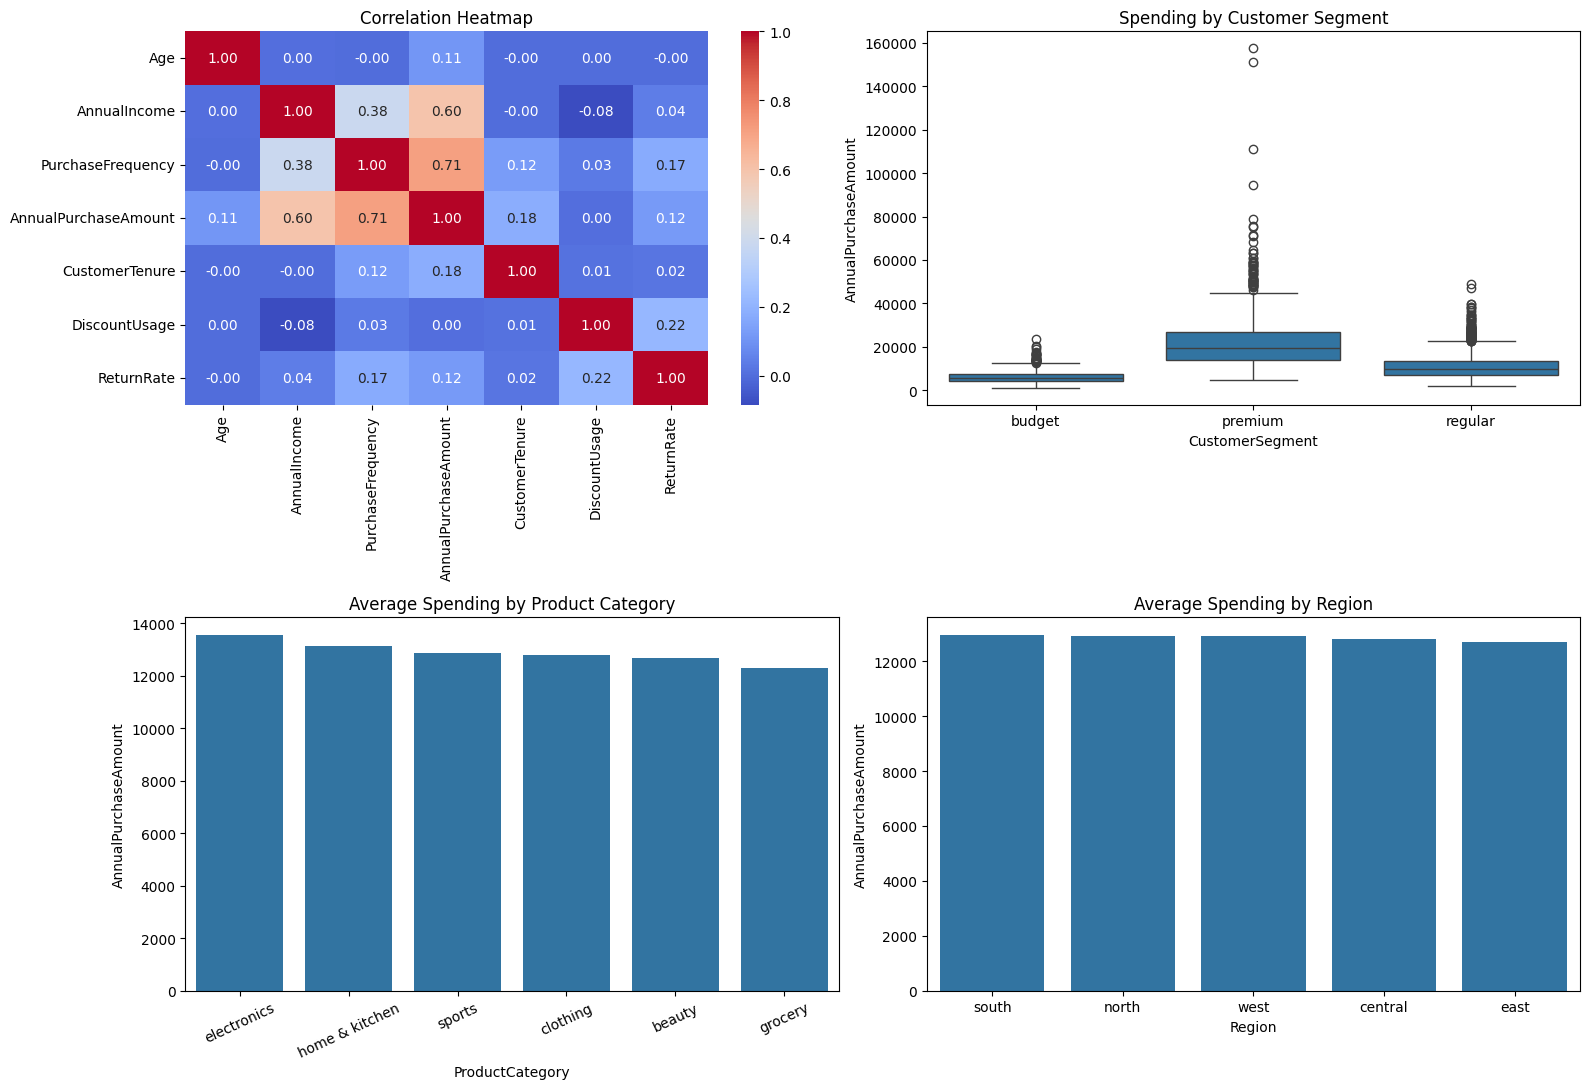

In [77]:
num_cols = [
    "Age", "AnnualIncome", "PurchaseFrequency",
    "AnnualPurchaseAmount", "CustomerTenure",
    "DiscountUsage", "ReturnRate"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Correlation heatmap
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            ax=axes[0, 0])
axes[0, 0].set_title("Correlation Heatmap")

# 2. Spending by customer segment
data = df.sample(min(5000, len(df)), random_state=42)
sns.boxplot(data=data, x="CustomerSegment",
            y="AnnualPurchaseAmount", ax=axes[0, 1])
axes[0, 1].set_title("Spending by Customer Segment")

# 3. Average spending by product category
cat_spend = (
    df.groupby("ProductCategory")["AnnualPurchaseAmount"]
    .mean().sort_values(ascending=False).reset_index()
)
sns.barplot(data=cat_spend, x="ProductCategory",
            y="AnnualPurchaseAmount", ax=axes[1, 0])
axes[1, 0].set_title("Average Spending by Product Category")
axes[1, 0].tick_params(axis="x", rotation=25)

# 4. Average spending by region
region_spend = (
    df.groupby("Region")["AnnualPurchaseAmount"]
    .mean().sort_values(ascending=False).reset_index()
)
sns.barplot(data=region_spend, x="Region",
            y="AnnualPurchaseAmount", ax=axes[1, 1])
axes[1, 1].set_title("Average Spending by Region")

plt.tight_layout()
plt.show()

In [78]:
region_stats = df.groupby("Region")["AnnualPurchaseAmount"].agg(
    ["count", "mean", "sum"]
).round(2)

print(region_stats)

          count      mean           sum
Region                                 
central   79050  12815.71  1.013082e+09
east      79553  12717.37  1.011705e+09
north    118902  12937.62  1.538309e+09
south    113937  12951.61  1.475668e+09
west     104065  12936.80  1.346268e+09


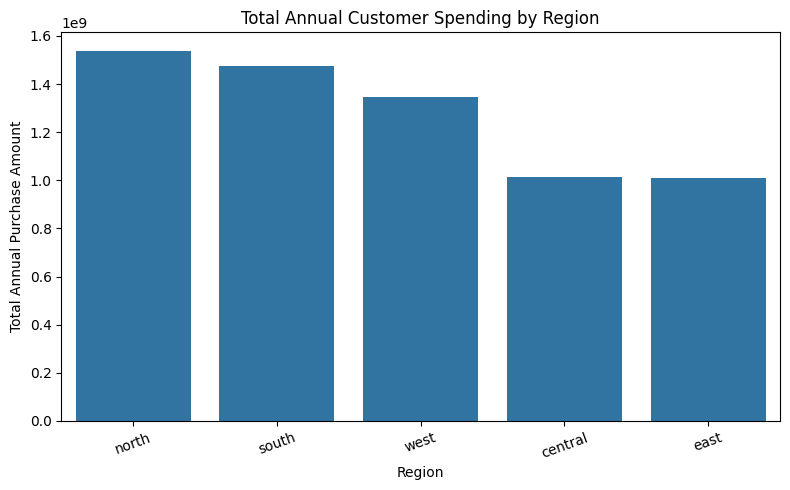

In [79]:
region_sales = (
    df.groupby("Region")["AnnualPurchaseAmount"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(8, 5))
sns.barplot(data=region_sales, x="Region", y="AnnualPurchaseAmount")
plt.title("Total Annual Customer Spending by Region")
plt.xlabel("Region")
plt.ylabel("Total Annual Purchase Amount")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Average Annual Spending by Segment:
CustomerSegment
premium    22253.33
regular    11042.66
budget      6239.72
Name: AnnualPurchaseAmount, dtype: float64


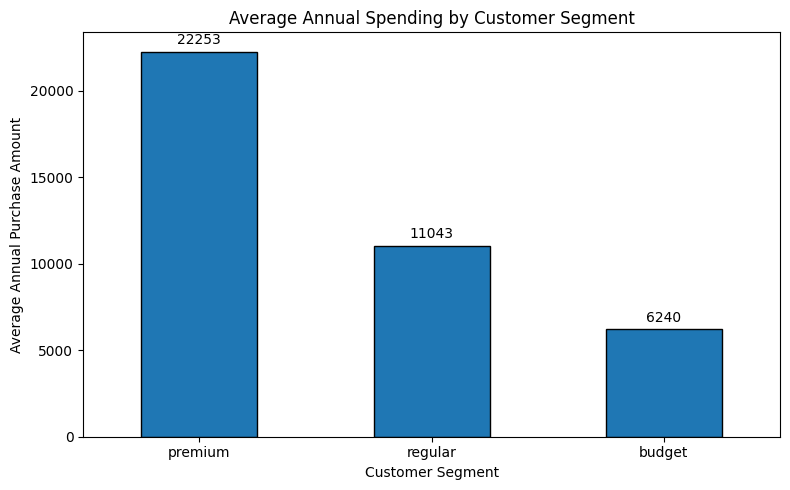

In [80]:
segment_spending = (
    df.groupby("CustomerSegment")["AnnualPurchaseAmount"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Annual Spending by Segment:")
print(segment_spending.round(2))

plt.figure(figsize=(8, 5))
ax = segment_spending.plot(kind="bar", edgecolor="black")

plt.title("Average Annual Spending by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Annual Purchase Amount")
plt.xticks(rotation=0)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

In [81]:
fig = px.histogram(
    df,
    x="Region",
    color="CustomerSegment",
    barmode="group",
    title="Customer Segments by Region"
)
fig.show()

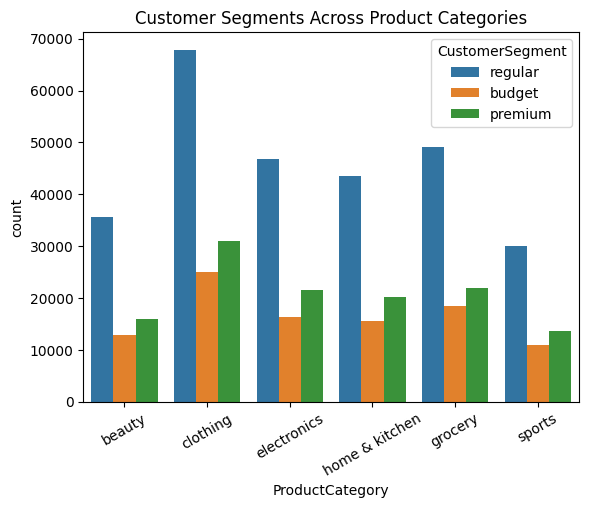

In [82]:
sns.countplot(
    data=df,
    x="ProductCategory",
    hue="CustomerSegment"
)

plt.xticks(rotation=30)
plt.title("Customer Segments Across Product Categories")
plt.show()

In [82]:
# ## Business Insights

# 1. **Customer Segmentation:** Premium customers have the highest average annual spending, followed by Regular and Budget customers.
#  This can support targeted marketing strategies for different customer groups.

# 2. **Spending Prediction:** PurchaseFrequency (correlation: 0.71) and AnnualIncome (correlation: 0.60) show the strongest positive
# relationships with AnnualPurchaseAmount among the numerical features examined. These features may be useful for spending prediction.

# 3. **Product Categories:** Electronics has the highest average annual spending among the product categories shown, while Grocery has
#  the lowest. Category-specific promotions can be investigated to improve customer engagement.

# 4. **Regional Analysis:** Average spending is relatively similar across regions, with South highest and East lowest. North has the
# highest total customer spending, supported in part by its larger customer count.

# 5. **Data Quality:** The dataset contains 499,000 rows and no duplicate rows. Some features still have missing values, which should
#  be handled appropriately before model training.

# 6. **Business Recommendation:** Use customer segments, purchase frequency, income, and regional spending patterns to guide targeted
#  marketing and customer analysis.